# <span style="color: #a855f7">Data visualization</span>

<span style="color: #a855f7">лінійні графіки, гістограма, boxplot, дві шкали Y, сітка підграфіків 2×2

<spam> всі графіки будуються через Matplotlib</span>

In [1]:
from datetime import date, timedelta

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
from cycler import cycler
from matplotlib.ticker import MaxNLocator

COLORS = ["#a855f7", "#e9d5ff", "#e879c6"]

plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "figure.facecolor": "#111116",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#746a80",
    "axes.labelcolor": "#e9d5ff",
    "axes.titlecolor": "#e9d5ff",
    "axes.titlesize": 13,
    "axes.titlepad": 14,
    "axes.prop_cycle": cycler(color=COLORS),
    "text.color": "#e9d5ff",
    "xtick.color": "#d8c8ed",
    "ytick.color": "#d8c8ed",
    "grid.color": "#746a80",
    "grid.alpha": 0.25,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "font.size": 10,
})

## <span style="color: #a855f7">Planned and actual sales</span>

<span style="color: #a855f7">два ряди на одній області, місяці на осі X, продажі - Y, окремі кольори, маркери, легенда</span>

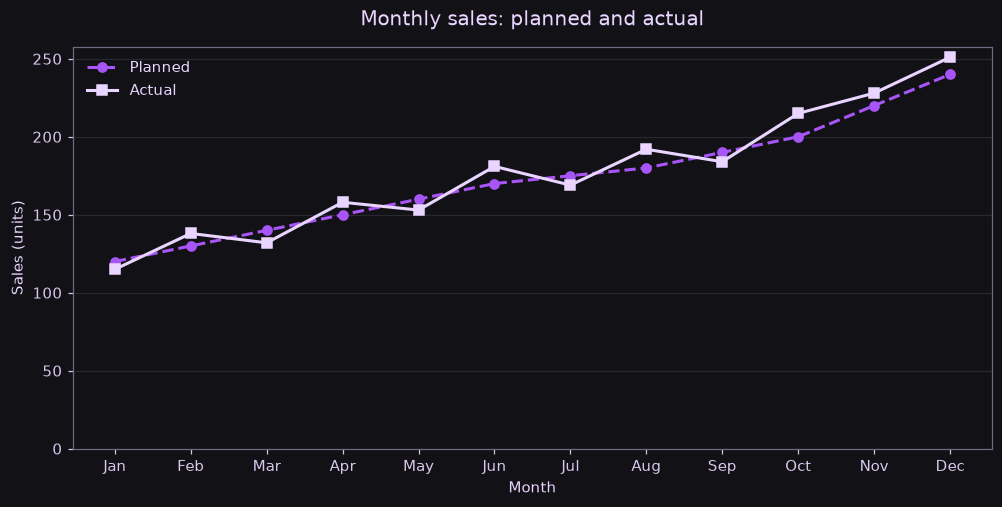

In [2]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
planned_sales = [120, 130, 140, 150, 160, 170, 175, 180, 190, 200, 220, 240]
actual_sales = [115, 138, 132, 158, 153, 181, 169, 192, 184, 215, 228, 251]

fig, ax = plt.subplots(layout="constrained")
ax.plot(months, planned_sales, marker="o", linestyle="--", label="Planned")
ax.plot(months, actual_sales, marker="s", label="Actual")
ax.set(title="Monthly sales: planned and actual", xlabel="Month", ylabel="Sales (units)")
ax.set_ylim(bottom=0)
ax.grid(axis="y")
ax.legend()
plt.show()

## <span style="color: #a855f7">Age distribution</span>

<span style="color: #a855f7">100 цілих значень віку, гістограма к-сті людей за інтервалами, вертикальна лінія avg, фіксований seed зберігає відтворюваність вибірки</span>

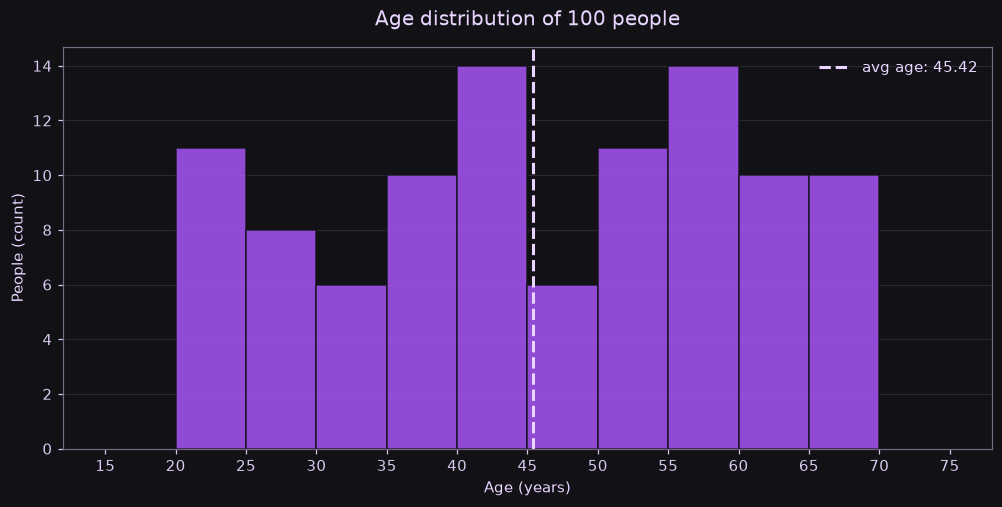

In [3]:
rng = np.random.default_rng(42)
ages = rng.integers(18, 71, size=100)
avg_age = ages.mean()
age_bins = [float(age) for age in range(15, 76, 5)]

fig, ax = plt.subplots(layout="constrained")
age_counts, bin_edges, bars = ax.hist(
    ages, bins=age_bins, color=COLORS[0], edgecolor="#111116", alpha=0.85
)
ax.axvline(avg_age, color=COLORS[1], linestyle="--", label=f"avg age: {avg_age:.2f}")
ax.set(title="Age distribution of 100 people", xlabel="Age (years)", ylabel="People (count)")
ax.set_xticks(age_bins)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend()
plt.show()

## <span style="color: #a855f7">Exam score spread</span>

<span style="color: #a855f7">3 вибірки по 12 оцінок, boxplot поруч для порівняння медіан, квартилів, розкиду, викидів</span>

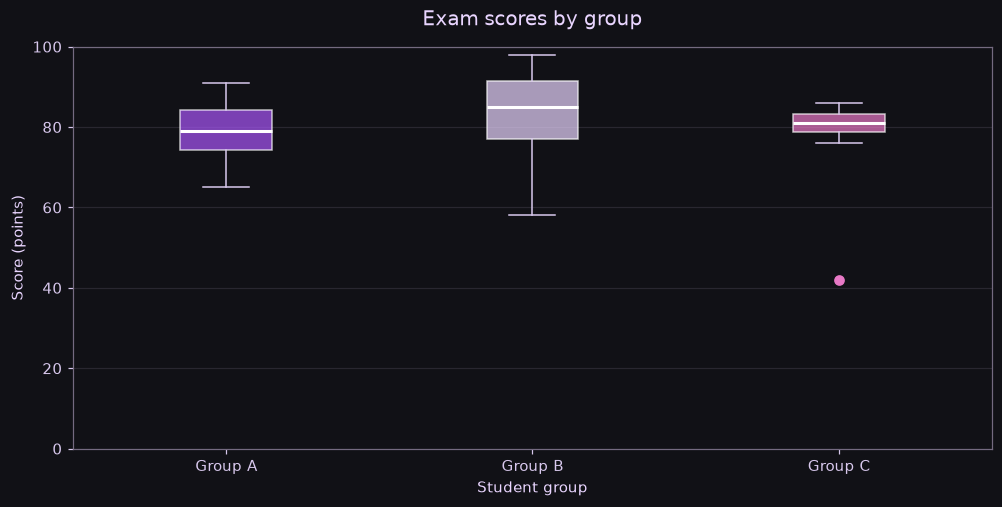

In [4]:
group_a = [65, 70, 72, 75, 77, 78, 80, 82, 84, 85, 88, 91]
group_b = [58, 68, 74, 78, 81, 84, 86, 89, 91, 93, 95, 98]
group_c = [42, 76, 78, 79, 80, 81, 81, 82, 83, 84, 85, 86]
exam_groups = [group_a, group_b, group_c]

fig, ax = plt.subplots(layout="constrained")
boxplot = ax.boxplot(
    exam_groups,
    tick_labels=["Group A", "Group B", "Group C"],
    patch_artist=True,
    medianprops={"color": "#ffffff", "linewidth": 2},
    whiskerprops={"color": "#d8c8ed"},
    capprops={"color": "#d8c8ed"},
    flierprops={"marker": "o", "markerfacecolor": COLORS[2], "markeredgecolor": COLORS[2]},
)
for box, color in zip(boxplot["boxes"], COLORS, strict=True):
    box.set_facecolor(color)
    box.set_alpha(0.7)
ax.set(title="Exam scores by group", xlabel="Student group", ylabel="Score (points)")
ax.set_ylim(0, 100)
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">Temperature and humidity</span>

<span style="color: #a855f7">7 дат на спільній осі X, температура на лівій шкалі Y, вологість на правій, спільна легенда, поворот дат на 45°</span>

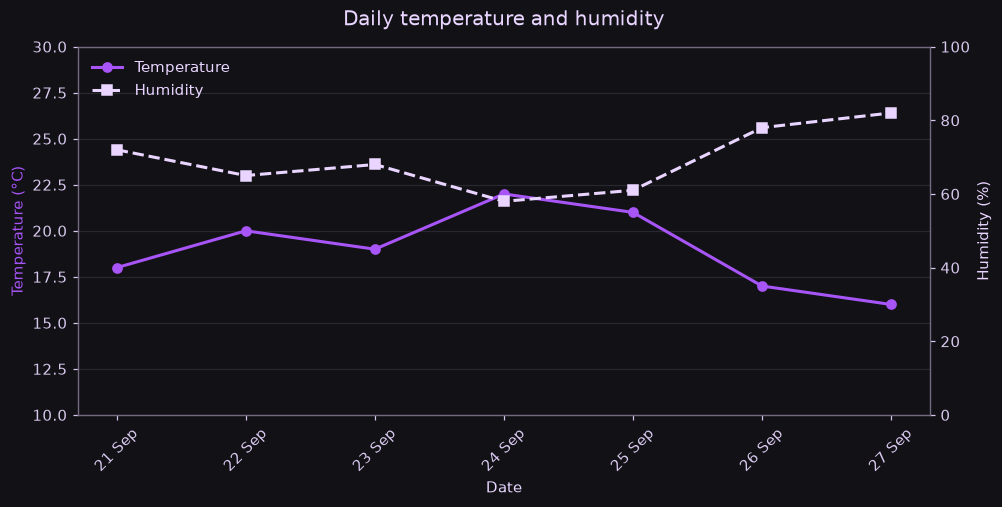

In [5]:
dates = [date(2026, 9, 21) + timedelta(days=offset) for offset in range(7)]
date_positions = mdates.date2num(dates)
temperature = [18, 20, 19, 22, 21, 17, 16]
humidity = [72, 65, 68, 58, 61, 78, 82]

fig, temperature_ax = plt.subplots(layout="constrained")
humidity_ax = temperature_ax.twinx()
temperature_line, = temperature_ax.plot(
    date_positions, temperature, color=COLORS[0], marker="o", label="Temperature"
)
humidity_line, = humidity_ax.plot(
    date_positions, humidity, color=COLORS[1], marker="s", linestyle="--", label="Humidity"
)
temperature_ax.set(title="Daily temperature and humidity", xlabel="Date", ylabel="Temperature (°C)")
humidity_ax.set_ylabel("Humidity (%)")
temperature_ax.set_ylim(10, 30)
humidity_ax.set_ylim(0, 100)
temperature_ax.yaxis.label.set_color(COLORS[0])
humidity_ax.yaxis.label.set_color(COLORS[1])
temperature_ax.xaxis.set_major_locator(mdates.DayLocator())
temperature_ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
temperature_ax.tick_params(axis="x", labelrotation=45)
temperature_ax.grid(axis="y")
temperature_ax.legend(handles=[temperature_line, humidity_line], loc="upper left")
plt.show()

## <span style="color: #a855f7">Hourly server load</span>

<span style="color: #a855f7">24 погодинні значення від 0 до 23, лінія навантаження, fill_between до Y = 0 і сітка</span>

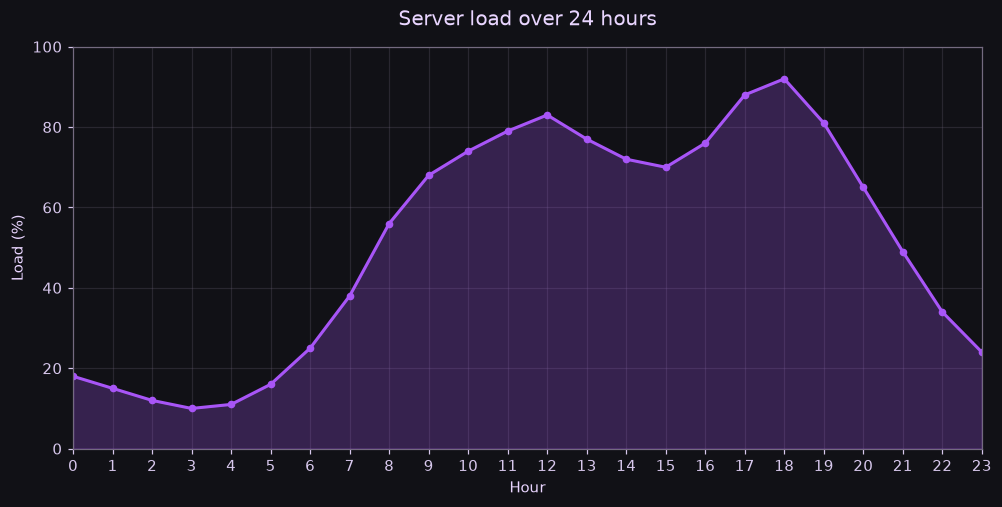

In [6]:
hours = list(range(24))
server_load = [18, 15, 12, 10, 11, 16, 25, 38, 56, 68, 74, 79, 83, 77, 72, 70, 76, 88, 92, 81, 65, 49, 34, 24]

fig, ax = plt.subplots(layout="constrained")
ax.plot(hours, server_load, color=COLORS[0], marker="o", markersize=4, label="Server load")
load_area = ax.fill_between(hours, server_load, 0, color=COLORS[0], alpha=0.25)
ax.set(title="Server load over 24 hours", xlabel="Hour", ylabel="Load (%)", xlim=(0, 23), ylim=(0, 100))
ax.set_xticks(hours)
ax.grid()
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">Product metrics dashboard</span>

<span style="color: #a855f7">4 ряди за спільною шкалою часу, підграфіки 2×2 з окремими одиницями вимірювання, заголовками і загальним заголовком</span>

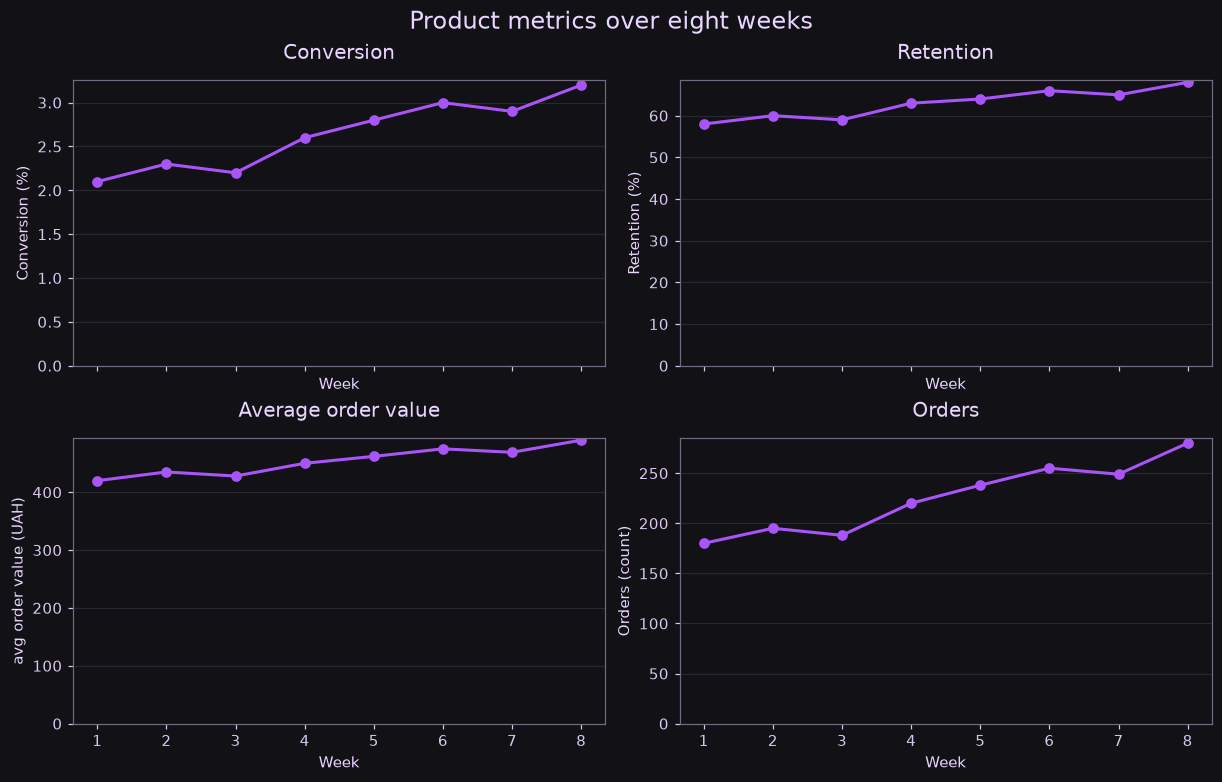

In [7]:
weeks = list(range(1, 9))
conversion = [2.1, 2.3, 2.2, 2.6, 2.8, 3.0, 2.9, 3.2]
retention = [58, 60, 59, 63, 64, 66, 65, 68]
avg_order_value = [420, 435, 428, 450, 462, 475, 469, 490]
order_counts = [180, 195, 188, 220, 238, 255, 249, 280]
metrics = [
    ("Conversion", conversion, "Conversion (%)"),
    ("Retention", retention, "Retention (%)"),
    ("Average order value", avg_order_value, "avg order value (UAH)"),
    ("Orders", order_counts, "Orders (count)"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, layout="constrained")
for ax, (title, values, ylabel) in zip(axes.flat, metrics, strict=True):
    ax.plot(weeks, values, marker="o", color=COLORS[0])
    ax.set(title=title, xlabel="Week", ylabel=ylabel)
    ax.set_xticks(weeks)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y")
fig.suptitle("Product metrics over eight weeks", fontsize=16)
plt.show()